<a href="https://colab.research.google.com/github/sushants05-ops/ECGR-4105---Intro-to-Machine-Learning/blob/main/ECGR_4105_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LOAN APPROVAL DATASET
Dataset shape: (4269, 13)

First five rows:
   loan_id  no_of_dependents     education self_employed  income_annum  \
0        1                 2      Graduate            No       9600000   
1        2                 0  Not Graduate           Yes       4100000   
2        3                 3      Graduate            No       9100000   
3        4                 3      Graduate            No       8200000   
4        5                 5  Not Graduate           Yes       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value loan_status  


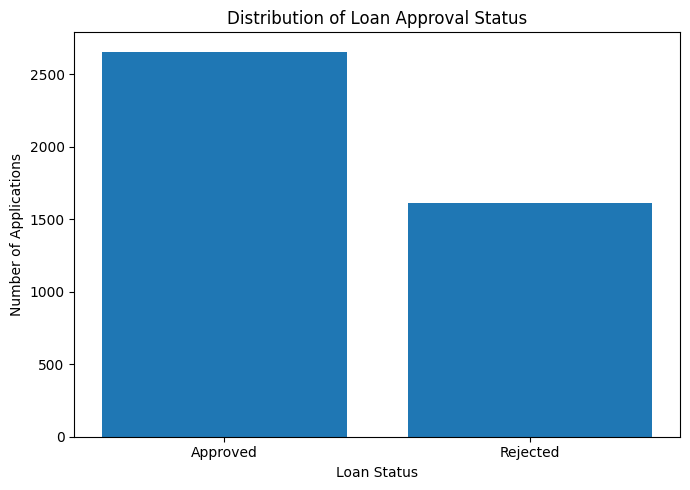

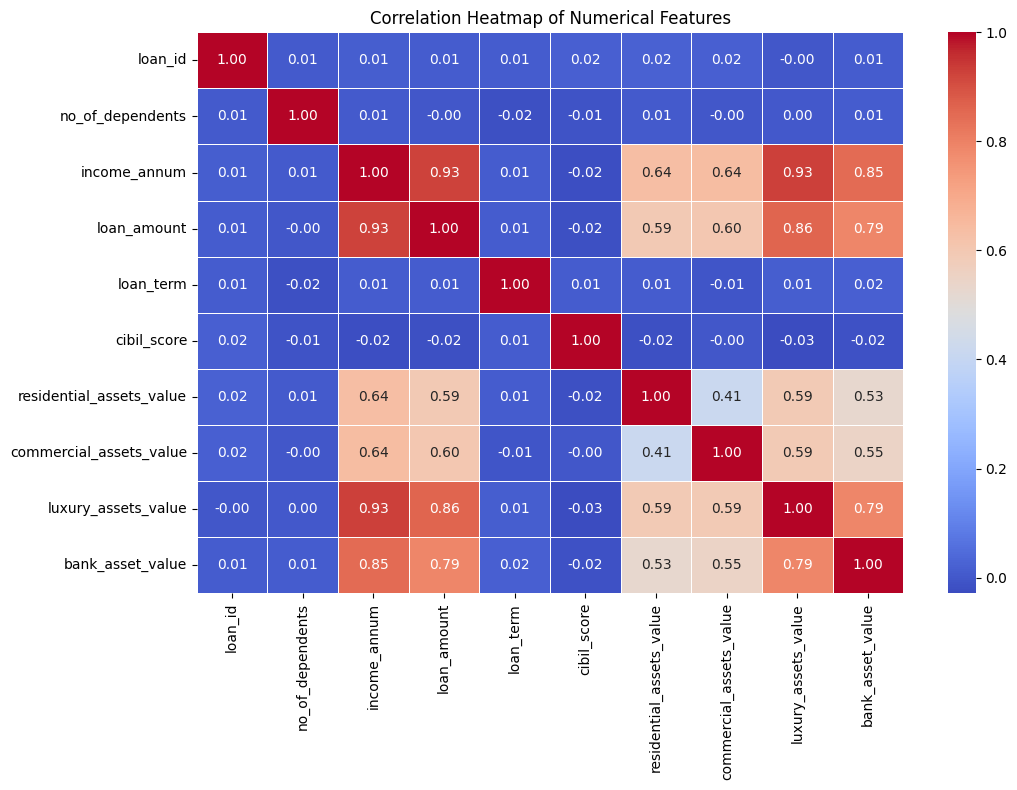


Numerical features:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Categorical features:
['education', 'self_employed']

Training set size: (3415, 11)
Testing set size: (854, 11)

Training target distribution:
loan_status
Approved    0.622255
Rejected    0.377745
Name: proportion, dtype: float64

Testing target distribution:
loan_status
Approved    0.62178
Rejected    0.37822
Name: proportion, dtype: float64

MAJORITY-CLASS BASELINE RESULTS
              precision    recall  f1-score   support

    Approved       0.62      1.00      0.77       531
    Rejected       0.00      0.00      0.00       323

    accuracy                           0.62       854
   macro avg       0.31      0.50      0.38       854
weighted avg       0.39      0.62      0.48       854


MODEL: Logistic Regression
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best p

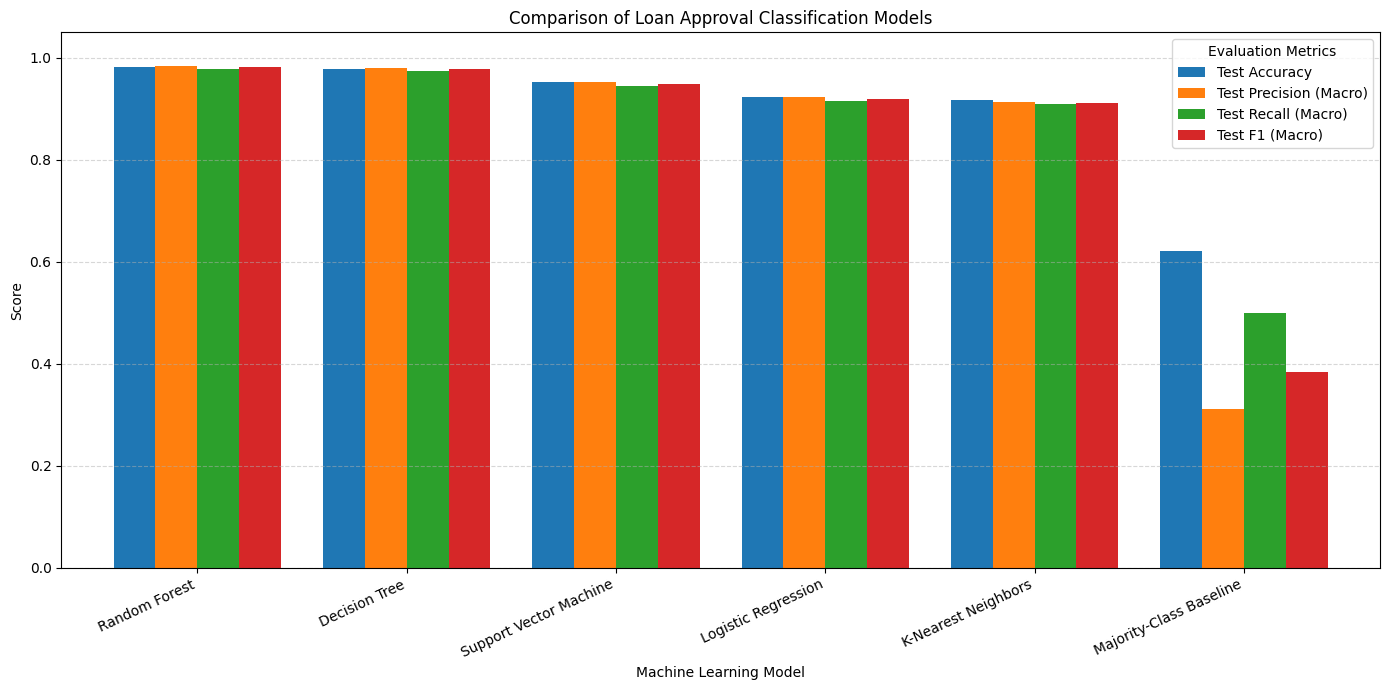

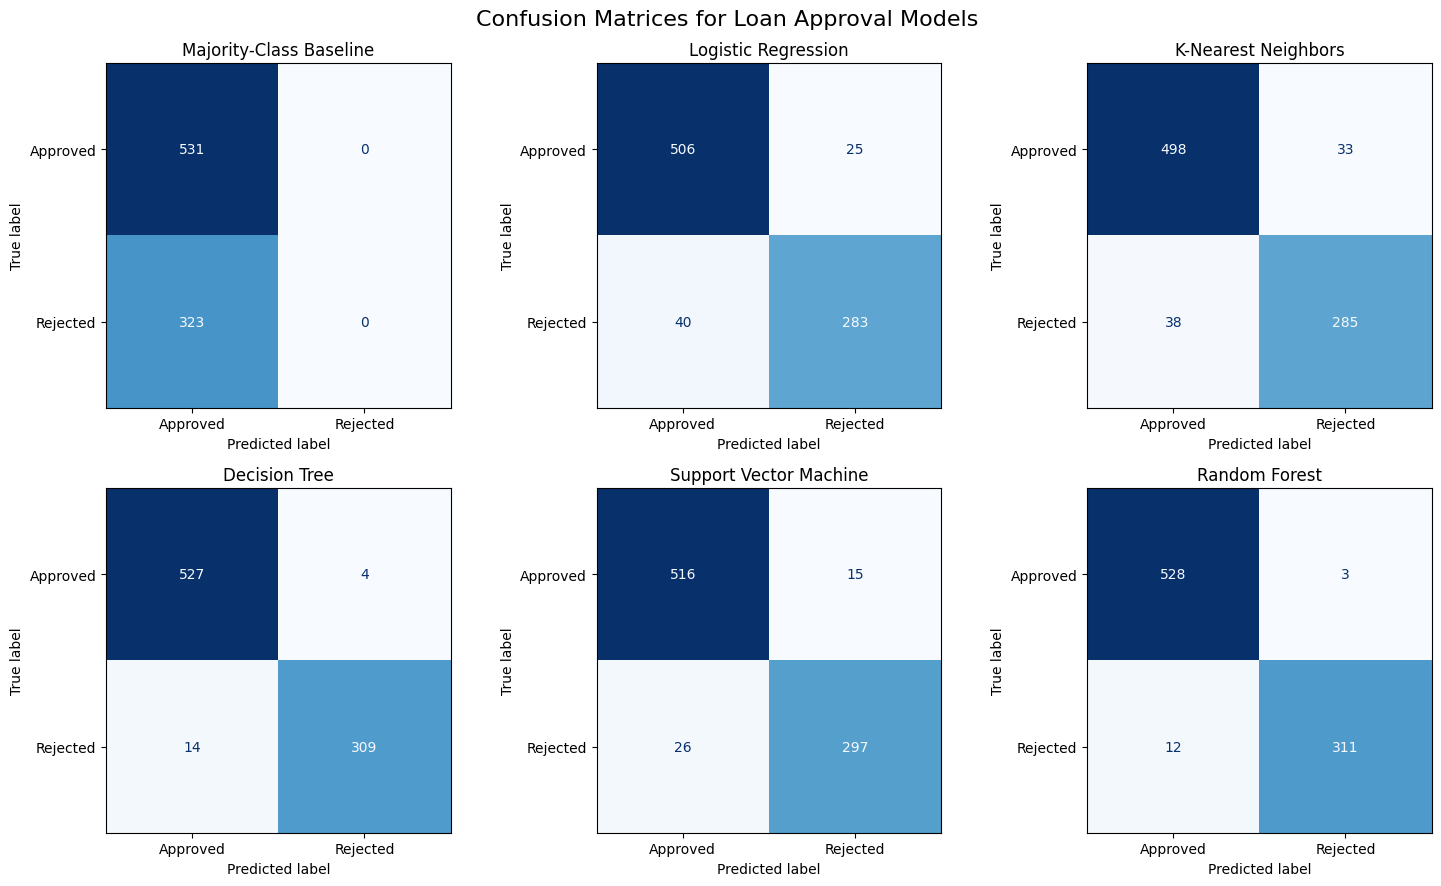


Top 15 Random Forest Features:
                      Feature  Importance
             num__cibil_score    0.800874
               num__loan_term    0.061805
             num__loan_amount    0.029242
     num__luxury_assets_value    0.019033
            num__income_annum    0.018535
num__residential_assets_value    0.018195
 num__commercial_assets_value    0.018145
        num__bank_asset_value    0.016980
        num__no_of_dependents    0.008524
        cat__self_employed_No    0.002437
       cat__self_employed_Yes    0.002288
  cat__education_Not Graduate    0.002019
      cat__education_Graduate    0.001922


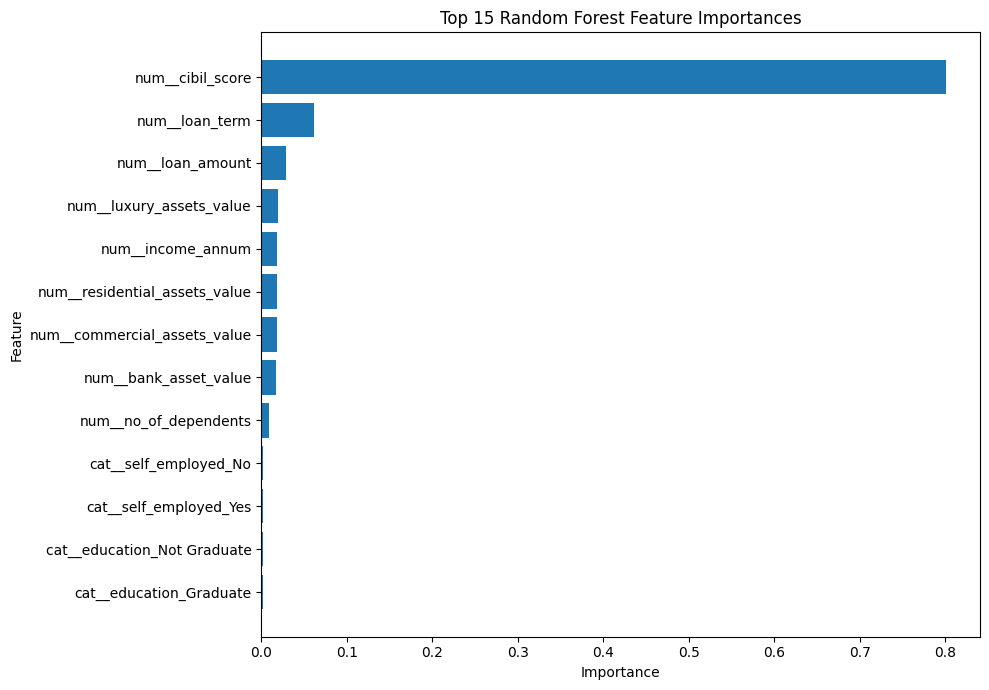


Model used for learning curve: Random Forest


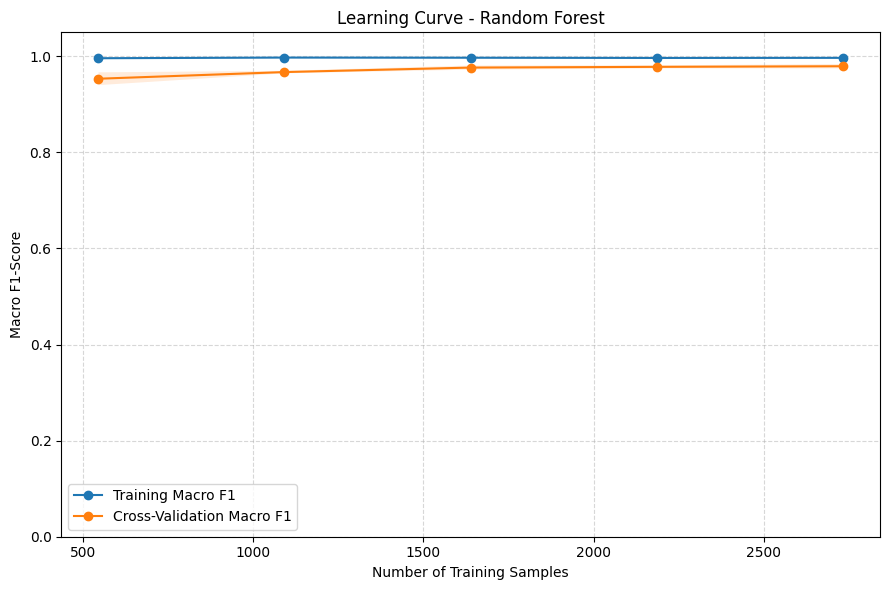


PROJECT EXECUTION COMPLETED
Dataset records used: 4269
Number of input features: 11
Training records: 3415
Testing records: 854
Target classes: ['Approved', 'Rejected']
Best model by test macro F1: Random Forest
Best test macro F1: 0.9812


In [3]:
# ECGR 4105 Final Project: Loan Eligibility Using Machine Learning
# Team Members: Sushant Suresh and Krupa Patel
# Dataset: loan_approval_dataset (1).csv

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
OUTPUT_DIR = "loan_project_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. LOAD DATASET
FILE_PATH = "loan_approval_dataset (1).csv"

df = pd.read_csv(FILE_PATH)

# Remove extra spaces from column names and text values
df.columns = df.columns.str.strip()

for column in df.select_dtypes(include=["object"]).columns:
    df[column] = df[column].astype("string").str.strip()

print("=" * 70)
print("LOAN APPROVAL DATASET")
print("=" * 70)
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nColumn information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["loan_status"].value_counts(dropna=False))

# 2. DATA CLEANING
TARGET = "loan_status"

if TARGET not in df.columns:
    raise ValueError(
        "The target column 'loan_status' was not found. "
        "Check the CSV file and its column names."
    )

# Remove rows with a missing target because the target cannot be imputed
df = df.dropna(subset=[TARGET]).copy()

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Remove rows with blank target labels, if any
df[TARGET] = df[TARGET].astype(str).str.strip()
df = df[df[TARGET] != ""].copy()

# This dataset uses Approved and Rejected as its target classes
print("\nTarget classes:", sorted(df[TARGET].unique()))

# 3. EXPLORATORY DATA ANALYSIS
print("\nDescriptive statistics:")
print(df.describe(include="all").T)

# Target class distribution
plt.figure(figsize=(7, 5))
target_counts = df[TARGET].value_counts()
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title("Distribution of Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "target_distribution.png"), dpi=300)
plt.show()

# Correlation heatmap for numerical columns
numeric_for_corr = df.select_dtypes(include=np.number)

if numeric_for_corr.shape[1] > 1:
    plt.figure(figsize=(11, 8))
    sns.heatmap(
        numeric_for_corr.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "correlation_heatmap.png"), dpi=300)
    plt.show()

# 4. DEFINE FEATURES AND TARGET
columns_to_drop = [TARGET]
if "loan_id" in df.columns:
    columns_to_drop.append("loan_id")

X = df.drop(columns=columns_to_drop)
y = df[TARGET]

# Detect numerical and categorical columns automatically.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

print("\nNumerical features:")
print(numeric_features)
print("\nCategorical features:")
print(categorical_features)

# 5. TRAINING AND TESTING SPLIT (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining set size:", X_train.shape)
print("Testing set size:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# 6. PREPROCESSING PIPELINE
# Numerical data:
# Replace missing values with the median.
# Standardize features for scale-sensitive algorithms.
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical data:
# Replace missing values with the most frequent category.
# Convert categories into numerical indicator columns.
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# 7. FIVE-FOLD STRATIFIED CROSS-VALIDATION
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Macro F1 gives equal importance to each target class
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

# 8. DEFINE FIVE MACHINE LEARNING MODELS AND SEARCH GRIDS
models_and_parameters = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        "parameters": {
            "classifier__C": [0.01, 0.1, 1, 10, 100]
        }
    },

    "K-Nearest Neighbors": {
        "model": KNeighborsClassifier(),
        "parameters": {
            "classifier__n_neighbors": [3, 5, 7, 9],
            "classifier__weights": ["uniform", "distance"],
            "classifier__metric": ["euclidean", "manhattan"]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        "parameters": {
            "classifier__max_depth": [None, 5, 10, 20],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__min_samples_leaf": [1, 2, 4]
        }
    },

    "Support Vector Machine": {
        "model": SVC(),
        "parameters": [
            {
                "classifier__kernel": ["linear"],
                "classifier__C": [0.1, 1, 10, 100]
            },
            {
                "classifier__kernel": ["rbf"],
                "classifier__C": [0.1, 1, 10, 100],
                "classifier__gamma": ["scale", "auto"]
            }
        ]
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "parameters": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_leaf": [1, 2]
        }
    }
}

# 9. MAJORITY-CLASS BASELINE
baseline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(
    y_test, baseline_predictions, average="macro", zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_predictions, average="macro", zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_predictions, average="macro", zero_division=0
)

results = [{
    "Model": "Majority-Class Baseline",
    "CV Accuracy": np.nan,
    "CV Macro F1": np.nan,
    "Test Accuracy": baseline_accuracy,
    "Test Precision (Macro)": baseline_precision,
    "Test Recall (Macro)": baseline_recall,
    "Test F1 (Macro)": baseline_f1,
    "Best Parameters": "Most frequent class"
}]

print("\n" + "=" * 70)
print("MAJORITY-CLASS BASELINE RESULTS")
print("=" * 70)
print(classification_report(y_test, baseline_predictions, zero_division=0))

# 10. TRAIN, TUNE, AND EVALUATE FIVE MODELS
best_estimators = {}
predictions_by_model = {
    "Majority-Class Baseline": baseline_predictions
}

for model_name, model_info in models_and_parameters.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    # Every model uses the same preprocessing steps.
    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model_info["model"])
        ]
    )

    # GridSearchCV performs stratified five-fold cross-validation
    grid_search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=model_info["parameters"],
        scoring=scoring,
        refit="f1_macro",
        cv=cv,
        n_jobs=1,
        verbose=1,
        return_train_score=False
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_estimators[model_name] = best_model

    # Evaluate the selected model on the untouched test set
    y_pred = best_model.predict(X_test)
    predictions_by_model[model_name] = y_pred

    test_accuracy = accuracy_score(y_test, y_pred)
    test_precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    test_recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    test_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    best_index = grid_search.best_index_
    cv_accuracy = grid_search.cv_results_["mean_test_accuracy"][best_index]
    cv_f1 = grid_search.cv_results_["mean_test_f1_macro"][best_index]

    results.append({
        "Model": model_name,
        "CV Accuracy": cv_accuracy,
        "CV Macro F1": cv_f1,
        "Test Accuracy": test_accuracy,
        "Test Precision (Macro)": test_precision,
        "Test Recall (Macro)": test_recall,
        "Test F1 (Macro)": test_f1,
        "Best Parameters": str(grid_search.best_params_)
    })

    print("\nBest parameters:")
    print(grid_search.best_params_)

    print("\nBest cross-validation macro F1:")
    print(grid_search.best_score_)

    print("\nTest classification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

# 11. MODEL COMPARISON TABLE
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Test F1 (Macro)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)
print(results_df.to_string(index=False))

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison_results.csv"),
    index=False
)
ml_results = results_df[
    results_df["Model"].isin(models_and_parameters.keys())
]
best_model_name = ml_results.iloc[0]["Model"]
best_model_f1 = ml_results.iloc[0]["Test F1 (Macro)"]

print("\nBest-performing model on the test set:", best_model_name)
print("Test macro F1-score:", best_model_f1)

# 12. MODEL PERFORMANCE COMPARISON GRAPH
metric_columns = [
    "Test Accuracy",
    "Test Precision (Macro)",
    "Test Recall (Macro)",
    "Test F1 (Macro)"
]

plot_results = results_df.set_index("Model")[metric_columns]

ax = plot_results.plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Comparison of Loan Approval Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "model_performance_comparison.png"),
    dpi=300
)
plt.show()

# 13. CONFUSION MATRICES FOR ALL MODELS
class_labels = sorted(y.unique())
number_of_models = len(predictions_by_model)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)
axes = axes.flatten()

for index, (model_name, y_pred) in enumerate(
    predictions_by_model.items()
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(
        ax=axes[index],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[index].set_title(model_name)

# Hide any unused subplot
for index in range(number_of_models, len(axes)):
    axes[index].set_visible(False)

plt.suptitle("Confusion Matrices for Loan Approval Models", fontsize=16)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "all_confusion_matrices.png"),
    dpi=300
)
plt.show()

# Save individual confusion matrix values
for model_name, y_pred in predictions_by_model.items():
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in class_labels],
        columns=[f"Predicted {label}" for label in class_labels]
    )
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    cm_df.to_csv(
        os.path.join(OUTPUT_DIR, f"{safe_name}_confusion_matrix.csv")
    )

# 14. RANDOM FOREST FEATURE IMPORTANCE
random_forest_model = best_estimators["Random Forest"]
transformed_feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importances = (
    random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": feature_importances
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 15 Random Forest Features:")
print(importance_df.head(15).to_string(index=False))

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "random_forest_feature_importance.csv"),
    index=False
)

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "random_forest_feature_importance.png"),
    dpi=300
)
plt.show()

# 15. TRAINING-DATA-SIZE EXPERIMENT
best_cv_model_name = max(
    best_estimators,
    key=lambda name: next(
        row["CV Macro F1"] for row in results
        if row["Model"] == name
    )
)

learning_curve_model = best_estimators[best_cv_model_name]

print("\nModel used for learning curve:", best_cv_model_name)

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=learning_curve_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

plt.figure(figsize=(9, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Macro F1"
)
plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Cross-Validation Macro F1"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)
plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.title(f"Learning Curve - {best_cv_model_name}")
plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1-Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_data_size_learning_curve.png"),
    dpi=300
)
plt.show()


# 16. FINAL SUMMARY
print("\n" + "=" * 70)
print("PROJECT EXECUTION COMPLETED")
print("=" * 70)

print("Dataset records used:", len(df))
print("Number of input features:", X.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Target classes:", class_labels)
print("Best model by test macro F1:", best_model_name)
print("Best test macro F1:", round(best_model_f1, 4))


